# IPO Listing Gain Prediction

**Notebook 1 of 5 - Data Collection & Cleaning**

## Problem Statement

**Problem:** Predict how much an Indian mainboard IPO will gain (or lose) on its listing day, using only
information that is available *before* it lists - subscription numbers, issue size and market mood.

**Why it matters:** A retail investor has to decide whether to apply before the IPO lists. Listing day returns
range from about -40% to +250%, so a good estimate (and a realistic range) helps decide which IPOs are worth
applying for.

## Data Sources

| # | Source | What it gives | Used for |
|---|---|---|---|
| 1 | Kaggle - *IPO Data India 2010-2026* (karanammithul) | QIB / HNI / Retail subscription, issue size, offer price, listing price | main dataset |
| 2 | NSE - `EQUITY_L.csv`, `SME_EQUITY_L.csv` | symbol and listing date of every listed company | finding the ticker of each IPO |
| 3 | Yahoo Finance (`yfinance`) | listing day open / close | cross checking Kaggle's listing price |

## Steps in this Notebook

1. Load and inspect the Kaggle file
2. Clean it - columns, datatypes, duplicates, missing values, outliers
3. Find the NSE symbol of each IPO
4. Get the listing day price from Yahoo Finance
5. Cross check Kaggle vs NSE price and build the target
6. Drop rows that don't belong and save the clean file

In [1]:
# import libraries
# pandas / numpy for tables and maths, matplotlib + seaborn for plots
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# helper functions from class (missing value table and outlier table)
from useful_func import missing_info, out_info

# os -> check if a file exists, re -> clean text, time -> small wait between downloads
import os
import re
import time
# yfinance -> prices from Yahoo Finance, rapidfuzz -> score how similar two names are
import yfinance as yf
from rapidfuzz import fuzz

# show all columns when printing a dataframe (default hides the middle ones)
pd.set_option("display.max_columns", 50)

## Step 1: Load and Inspect the Kaggle Data

**What we do:** Read the excel file and look at its shape, columns, datatypes and basic statistics.

**Why we do it:** Knowing the structure first tells us which columns are usable, what needs type conversion and
where the problems are.

*Note:* the Kaggle zip has 2 excel files - the "Updated" one goes till May 2026, so using that one.

In [2]:
# read dataset
# kaggle file, one row = one IPO (2010 to May 2026)
raw = pd.read_excel("../data/raw/kaggle/Initial Public Offering (Updated).xlsx")
raw.head()

,Date,IPO_Name,Issue_Size(crores),QIB,HNI,RII,Total,Offer Price,List Price,Listing Gain,CMP(BSE),CMP(NSE),Current Gains
0,2026-05-14,Bagmane Prime Offi...,3405.00,17.09,15.79,0.00,16.50,100,103.4,3.40,103.92,103.97,3.92
1,2026-05-08,Onemi Technology S...,925.92,24.87,6.57,2.03,9.50,171,191.0,11.70,231.70,231.74,35.50
2,2026-04-29,Citius Transnet In...,1105.00,8.54,11.77,0.00,10.01,100,104.5,4.50,105.87,106.04,5.87
3,2026-04-17,Om Power Transmiss...,150.06,3.65,7.06,1.54,3.33,175,181.1,3.49,190.80,190.74,9.03
4,2026-04-02,Sai Parenteral's L...,408.79,1.71,2.36,0.12,1.05,392,405.0,3.32,487.10,486.70,24.26


In [3]:
# (rows, columns)
raw.shape

(652, 13)

In [4]:
# column names, datatypes and how many non-null values each column has
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 652 entries, 0 to 651
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                652 non-null    datetime64[ns]
 1   IPO_Name            652 non-null    object        
 2   Issue_Size(crores)  652 non-null    float64       
 3   QIB                 650 non-null    float64       
 4   HNI                 650 non-null    float64       
 5   RII                 650 non-null    float64       
 6   Total               650 non-null    float64       
 7   Offer Price         652 non-null    int64         
 8   List Price          652 non-null    float64       
 9   Listing Gain        650 non-null    float64       
 10  CMP(BSE)            650 non-null    float64       
 11  CMP(NSE)            642 non-null    float64       
 12  Current Gains       649 non-null    float64       
dtypes: datetime64[ns](1), float64(10), int64(1), objec

In [5]:
# min / max / mean of the number columns - quick look for strange values
raw.describe()

,Date,Issue_Size(crores),QIB,HNI,RII,Total,Offer Price,List Price,Listing Gain,CMP(BSE),CMP(NSE),Current Gains
count,652,652.000000,650.000000,650.000000,650.000000,650.000000,652.000000,652.000000,650.000000,650.000000,642.000000,649.000000
mean,2020-02-06 22:40:29.447852800,1444.556396,48.771169,71.257385,15.913738,37.167046,358.694785,419.785690,16.480338,633.441831,644.354019,73.202761
min,2010-01-04 00:00:00,23.000000,0.000000,0.000000,0.000000,0.110000,10.000000,0.000000,-38.890000,0.040000,0.050000,-99.930000
25%,2016-05-09 18:00:00,269.477500,2.630000,1.840000,1.402500,2.260000,121.750000,135.075000,-0.065000,119.925000,121.172500,-33.200000
50%,2021-11-18 00:00:00,599.785000,13.595000,13.350000,4.780000,10.765000,252.000000,286.625000,5.800000,285.750000,288.250000,12.310000
75%,2024-09-24 00:00:00,1272.290000,77.295000,76.345000,14.610000,56.617500,481.250000,548.500000,23.060000,671.050000,706.012500,91.380000
max,2026-05-14 00:00:00,27858.800000,420.570000,958.070000,374.810000,326.490000,2165.000000,2725.000000,252.760000,15924.100000,15892.000000,2523.670000
std,NaN,2628.744869,66.549173,130.586078,32.483974,52.977874,326.819563,415.339727,30.721293,1141.908775,1148.343680,243.124515


## Step 2: Data Cleaning

**What we do:**
1. Drop `CMP(BSE)`, `CMP(NSE)` and `Current Gains`
2. Rename columns to short, consistent names
3. Fix company names cut off with "..."
4. Convert datatypes
5. Check duplicates, missing values and outliers
6. Mark REITs / InvITs

**Why we do it:** `CMP` and `Current Gains` depend on the day the file was downloaded - they are not known on
listing day, so using them would be **data leakage**.

In [6]:
# old name -> new short name
# CMP(BSE), CMP(NSE) and Current Gains are not in this list on purpose:
# they are today's price (download date), nobody knows them on listing day -> data leakage
cols = {"Date": "listing_date", "IPO_Name": "ipo_name", "Issue_Size(crores)": "issue_size_cr",
        "QIB": "sub_qib", "HNI": "sub_hni", "RII": "sub_rii", "Total": "sub_total",
        "Offer Price": "offer_price", "List Price": "list_price", "Listing Gain": "listing_gain_pct"}
# keep only these columns and rename them
df = raw[list(cols)].rename(columns=cols)
df.dtypes

listing_date        datetime64[ns]
ipo_name                    object
issue_size_cr              float64
sub_qib                    float64
sub_hni                    float64
sub_rii                    float64
sub_total                  float64
offer_price                  int64
list_price                 float64
listing_gain_pct           float64
dtype: object

In [7]:
# names cut off with "..." at the end
# need full names later to find the NSE symbol, so first see how many are cut
df[df["ipo_name"].astype(str).str.strip().str.endswith("...")]["ipo_name"].head(10)

0     Bagmane Prime Offi...
1     Onemi Technology S...
2     Citius Transnet In...
3     Om Power Transmiss...
4     Sai Parenteral's L...
6     Amir Chand Jagdish...
7     Central Mine Plann...
8     GSP Crop Science L...
9     RaajMarg Infra Inv...
11    Rajputana Stainles...
Name: ipo_name, dtype: object

### Step 2.1: Cut-off Names and Datatypes

**What we do:** Remove the trailing "..." from names (and keep a `name_truncated` flag), convert the date to
datetime and all numbers to float.

**Why we do it:** The full name is needed in Step 3 to find the NSE symbol, and numeric columns must be numbers
before any analysis.

In [8]:
# remove the "..." from the end of the name
names = df["ipo_name"].astype(str).str.strip()
df["ipo_name"] = names.str.replace(r"\.\.\.$", "", regex=True).str.strip()
# remember which names were cut (True / False), matching step uses this
df["name_truncated"] = names.str.endswith("...")

# convert datatypes
# date text -> real date, so we can sort by time
df["listing_date"] = pd.to_datetime(df["listing_date"], errors="coerce")
num_cols = ["issue_size_cr", "sub_qib", "sub_hni", "sub_rii", "sub_total", "offer_price", "list_price",
            "listing_gain_pct"]
# all number columns -> float, anything that is not a number becomes NaN (errors="coerce")
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype(float)

df.dtypes

listing_date        datetime64[ns]
ipo_name                    object
issue_size_cr              float64
sub_qib                    float64
sub_hni                    float64
sub_rii                    float64
sub_total                  float64
offer_price                float64
list_price                 float64
listing_gain_pct           float64
name_truncated                bool
dtype: object

### Step 2.2: Duplicates and Missing Values

**What we do:** Count duplicate rows and missing values per column (`missing_info` from useful_func).

**Why we do it:** Duplicates would count the same IPO twice, and missing values have to be handled before
modelling.

In [9]:
# find duplicate rows
# check missing values
# check for outliers in continuous numeric columns

In [10]:
# count of rows that are exact copies of another row
df.duplicated().sum()

np.int64(0)

In [11]:
# missing count and % for every column (class helper)
missing_info(df)

,column_name,num_missing,missing%
0,sub_qib,2,0.31
1,sub_hni,2,0.31
2,sub_rii,2,0.31
3,sub_total,2,0.31
4,listing_gain_pct,2,0.31


In [12]:
# see the rows where subscription or listing gain is missing
# without these the row can't be used (no answer to learn from)
df[df["sub_total"].isna() | df["listing_gain_pct"].isna()]

,listing_date,ipo_name,issue_size_cr,sub_qib,sub_hni,sub_rii,sub_total,offer_price,list_price,listing_gain_pct,name_truncated
28,2025-12-15,Wakefit Innovation,1288.89,3.04,1.05,3.17,2.52,195.0,0.0,NaN,True
52,2025-10-10,Wework India Manag,3000.00,1.79,0.23,0.61,1.15,648.0,0.0,NaN,True
388,2020-08-07,Mindspace Business Parks REIT,4500.00,NaN,NaN,NaN,NaN,275.0,304.0,10.55,False
502,2015-11-02,Coffee Day Enterprises Ltd,1150.00,NaN,NaN,NaN,NaN,328.0,313.0,-4.57,False


**Observation:** Only 2 rows have missing subscription and 2 rows have missing listing gain (3 IPOs in total).

**Decision:** A missing target can't be filled, so these rows are dropped in Step 6.

### Step 2.3: Outliers

**What we do:** Check outliers in every numeric column with `out_info` (z-score for symmetric columns, IQR for
skewed ones) and look at boxplots.

**Why we do it:** Outliers can be data errors (fix / drop) or real extreme values (keep) - need to know which.

In [13]:
# outlier count and % per column (class helper, uses IQR or z-score depending on skew)
out_info(df[num_cols])

,col_name,method,num_out,out_%,ul,ll
0,issue_size_cr,iqr,90,13.80,2776.50875,-1234.74125
1,sub_hni,iqr,84,12.88,188.10250,-109.91750
2,sub_rii,iqr,81,12.42,34.42125,-18.40875
3,listing_gain_pct,iqr,55,8.44,57.74750,-34.75250
4,list_price,iqr,43,6.60,1168.63750,-485.06250
5,sub_total,iqr,41,6.29,138.15375,-79.27625
6,sub_qib,iqr,34,5.21,189.29250,-109.36750
7,offer_price,iqr,32,4.91,1020.50000,-417.50000


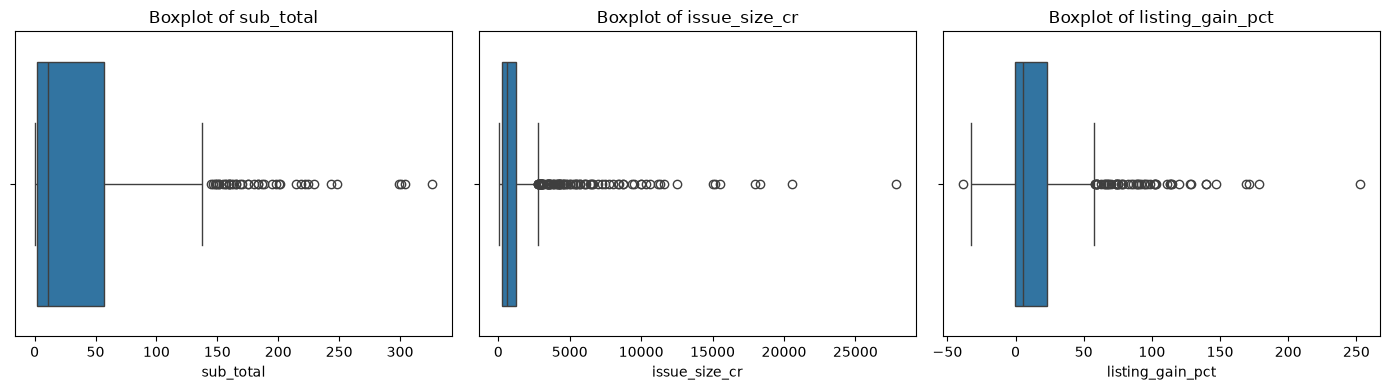

In [14]:
# boxplots for 3 important columns side by side
# dots outside the whiskers = outliers
plt.figure(figsize=(14, 4))
for i, col in enumerate(["sub_total", "issue_size_cr", "listing_gain_pct"]):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

**Observation:** The IQR method marks a lot of rows as outliers:

| Column | % outliers (IQR) |
|---|---|
| issue_size_cr | 13.8% |
| sub_hni | 12.9% |
| sub_rii | 12.4% |
| listing_gain_pct | 8.4% |
| sub_total | 6.3% |

**Decision - not removing outliers:**
- these are real IPOs, not data entry errors - 100x+ subscribed hot IPOs, and very big issues like
  Hyundai (Rs 27,859 cr) and LIC (Rs 20,557 cr)
- removing them would remove exactly the IPOs that matter most
- instead: use **log** of subscription and issue size in the model, and **MAE** as the metric
  (less sensitive to big errors than RMSE)

### Step 2.4: REITs and InvITs

Rows with retail (RII) subscription = 0 look strange, checking them:

In [15]:
# retail subscription = 0 looks wrong for an IPO, check which rows these are
df[df["sub_rii"] == 0][["listing_date", "ipo_name", "sub_qib", "sub_hni", "sub_rii", "sub_total"]]

,listing_date,ipo_name,sub_qib,sub_hni,sub_rii,sub_total
0,2026-05-14,Bagmane Prime Offi,17.09,15.79,0.0,16.50
2,2026-04-29,Citius Transnet In,8.54,11.77,0.0,10.01
9,2026-03-24,RaajMarg Infra Inv,11.61,2.55,0.0,7.49
50,2025-10-16,Anantam Highways T,2.49,7.29,0.0,4.67
90,2025-08-18,Knowledge Realty T,6.75,15.51,0.0,10.73
126,2025-01-17,Capital Infra Trust,0.58,4.24,0.0,2.23
196,2024-03-12,Indus Infra Trust,8.92,6.93,0.0,8.01
264,2023-05-19,Nexus Select Trust,0.00,0.00,0.0,3.61
356,2021-05-14,Powergrid Infrastructure Investment Trust,4.63,5.07,0.0,4.83
370,2021-02-16,Brookfield India Real Estate Trust,4.78,11.74,0.0,7.94


**Observation:** These are REITs / InvITs (trust units). They have no retail quota and a different investor
base, so they don't belong with normal company IPOs.

**Decision:** Mark them with `is_trust` (by name or RII = 0) and drop them in Step 6. Then sort by date and
give every IPO an id.

In [16]:
# REIT / InvIT are trusts, not companies -> flag them by name or by retail = 0
df["is_trust"] = df["ipo_name"].str.lower().str.contains(r"\b(?:reit|invit|trust)\b", regex=True) | (df["sub_rii"] == 0)

# sort by date (then name), mergesort keeps the order stable for same date
df = df.sort_values(["listing_date", "ipo_name"], kind="mergesort").reset_index(drop=True)
# give every IPO an id -> IPO0001, IPO0002, ...
df.insert(0, "ipo_id", ["IPO%04d" % i for i in range(1, len(df) + 1)])

print("trusts -:", df["is_trust"].sum())
print("cut off names -:", df["name_truncated"].sum())
print("date range -:", df["listing_date"].min().date(), "to", df["listing_date"].max().date())

trusts -: 14
cut off names -: 69
date range -: 2010-01-04 to 2026-05-14


In [17]:
df.head()

,ipo_id,listing_date,ipo_name,issue_size_cr,sub_qib,sub_hni,sub_rii,sub_total,offer_price,list_price,listing_gain_pct,name_truncated,is_trust
0,IPO0001,2010-01-04,JSW Energy Limited,2700.00,2.88,0.15,0.40,1.68,100.0,102.0,2.00,False,False
1,IPO0002,2010-01-05,Godrej Properties Limited,468.85,7.45,0.41,0.38,4.00,490.0,510.0,4.08,False,False
2,IPO0003,2010-01-06,D B Corp Limited,384.22,68.52,26.17,3.42,39.54,212.0,250.0,17.92,False,False
3,IPO0004,2010-01-11,MBL Infrastructure Limited,102.60,3.35,2.65,0.40,1.97,180.0,190.0,5.56,False,False
4,IPO0005,2010-01-29,Birla Shloka Edutech Limited,34.78,0.00,5.45,1.76,1.43,50.0,49.0,-2.00,False,False


In [18]:
# save cleaned kaggle table
df.to_csv("../data/interim/ipos_kaggle.csv", index=False)

## Step 3: Find the NSE Symbol of each IPO

**What we do:** Load NSE's list of all listed companies (mainboard + SME) and match each Kaggle IPO to it.

**Why we do it:** The Kaggle file has no ticker symbol, and without it we can't get prices from Yahoo Finance.

*Note:* NSE's archive (nsearchives.nseindia.com) returns 403 without a browser user agent.

In [19]:
# read one NSE list file and keep only the columns we need
def read_nse(path, segment):
    # read everything as text first, dates are fixed below
    t = pd.read_csv(path, dtype=str)
    # "NAME OF COMPANY" -> "name_of_company"
    t.columns = [c.strip().lower().replace(" ", "_") for c in t.columns]
    # remove extra spaces from every value
    t = t.apply(lambda col: col.str.strip())
    return pd.DataFrame({
        "symbol": t["symbol"],
        "company_name": t["name_of_company"],
        "series": t["series"],
        # NSE writes dates like 14-OCT-2019
        "listing_date": pd.to_datetime(t["date_of_listing"], format="%d-%b-%Y", errors="coerce"),
        "isin": t["isin_number"],
        "segment": segment
    })


# mainboard list + SME list in one table
nse = pd.concat([read_nse("../data/raw/nse/EQUITY_L.csv", "mainboard"),
                 read_nse("../data/raw/nse/SME_EQUITY_L.csv", "sme")], ignore_index=True)
nse.head()

,symbol,company_name,series,listing_date,isin,segment
0,20MICRONS,20 Microns Limited,EQ,2008-10-06,INE144J01027,mainboard
1,21STCENMGM,21st Century Management Services Limited,BE,1995-05-03,INE253B01015,mainboard
2,360ONE,360 ONE WAM LIMITED,EQ,2019-09-19,INE466L01038,mainboard
3,3BBLACKBIO,3B Blackbio Dx Limited,EQ,2026-04-20,INE994E01018,mainboard
4,3IINFOLTD,3i Infotech Limited,EQ,2021-10-22,INE748C01038,mainboard


In [20]:
nse.shape

(3230, 6)

In [21]:
# how many companies in each list
nse["segment"].value_counts()

segment
mainboard    2646
sme           584
Name: count, dtype: int64

**Problem:** Company names are written differently in the 2 files, so a direct merge on name doesn't work.

| Kaggle | NSE |
|---|---|
| Larsen & Toubro Infotech Ltd. | Larsen and Toubro Infotech Limited |
| Highway Infrastruc *(cut off)* | Highway Infrastructure Limited |

**Approach:**
1. Clean both names - lowercase, `&` -> `and`, remove words like Ltd / Limited / Pvt
2. Only look at NSE companies that listed **within 7 days** of the Kaggle listing date
3. Among those, pick the closest name with `rapidfuzz`, accept only if score **>= 85**

In [22]:
# common words that don't help in matching names
stop_words = {"limited", "ltd", "pvt", "private", "ipo", "the"}


# make two different ways of writing the same name look the same
def clean_name(name):
    if not isinstance(name, str):
        return ""
    # lowercase, "&" -> "and", anything that is not a letter / number -> space, then split into words
    words = re.sub(r"[^a-z0-9]+", " ", name.lower().replace("&", " and ")).split()
    # drop the stop words and join back
    return " ".join(w for w in words if w not in stop_words)


# test on two examples
clean_name("Larsen & Toubro Infotech Ltd."), clean_name("Tata Technologies Limited")

('larsen and toubro infotech', 'tata technologies')

In [23]:
# similarity of two cleaned names, 0 to 100 (take the best of 3 scores)
def name_score(a, b):
    if not a or not b:
        return 0.0
    s1 = fuzz.token_sort_ratio(a, b)        # word order
    s2 = fuzz.ratio(a, b[:len(a)])          # cut off names
    # token_set alone matched VMS Industries to PI Industries, so use it only when first word is same
    s3 = fuzz.token_set_ratio(a, b) if fuzz.ratio(a.split()[0], b.split()[0]) >= 85 else 0.0
    return float(max(s1, s2, s3))


# first should be low (different company), second high (cut off name)
name_score("vms industries", "pi industries"), name_score("highway infrastruc", "highway infrastructure")

(81.4814814814815, 100.0)

In [24]:
# clean all NSE names once (faster than cleaning inside the loop)
nse["clean"] = nse["company_name"].map(clean_name)
# only look at NSE companies listed within 7 days of the kaggle date
window = pd.Timedelta(days=7)

rows = []
for ipo in df.itertuples():
    name = clean_name(ipo.ipo_name)
    # default = not matched
    res = {"symbol": None, "nse_company_name": None, "segment": None, "nse_listing_date": pd.NaT,
           "match_score": 0.0, "match_method": "unmatched"}
    if pd.notna(ipo.listing_date) and name:
        # NSE companies that listed near this IPO's date
        near = nse[(nse["listing_date"] - ipo.listing_date).abs() <= window]
        if len(near):
            # score every nearby company and take the best one
            scores = near["clean"].map(lambda x: name_score(name, x))
            best = scores.idxmax()
            res["match_score"] = float(scores[best])
            # accept only 85+ -> better no symbol than a wrong symbol
            if scores[best] >= 85:
                res.update(symbol=near.loc[best, "symbol"], nse_company_name=near.loc[best, "company_name"],
                           segment=near.loc[best, "segment"], nse_listing_date=near.loc[best, "listing_date"],
                           match_method="name_and_date")
    rows.append(res)

# add the match columns next to the kaggle columns (same row order)
matched = pd.concat([df, pd.DataFrame(rows)], axis=1)
matched["match_method"].value_counts()

match_method
name_and_date    547
unmatched        105
Name: count, dtype: int64

In [25]:
# lowest scores that still got matched - checked these manually
matched[matched["match_method"] == "name_and_date"].sort_values("match_score")[
    ["ipo_name", "nse_company_name", "match_score"]].head(10)

,ipo_name,nse_company_name,match_score
428,Flair Writing Instruments Limited,Flair Writing Industries Limited,85.714286
254,Sterling and Wilson Solar Ltd,Sterling and Wilson Renewable Energy Limited,86.363636
243,Xelpmoc Design and Technologies Ltd,Xelpmoc Design And Tech Limited,87.804878
532,Quality Power Electronics Limited,Quality Power Electrical Equipments Limited,88.000000
67,RPP Infra Projects Ltd,R.P.P. Infra Projects Limited,88.888889
390,Ideaforge Technologies Limited,Ideaforge Technology Limited,90.476190
358,Syrma SGS Technologies,Syrma SGS Technology Limited,90.476190
512,International Gemmological Institute (India) L...,International Gemological Institute Limited,90.909091
426,Gandhar Oil Refineries Limited,Gandhar Oil Refinery (India) Limited,90.909091
647,Sai Parenteral's L,Sai Parenterals Limited,90.909091


In [26]:
# not matched -> mostly companies delisted / merged later, or listed only on BSE
matched[matched["match_method"] == "unmatched"][["listing_date", "ipo_name", "match_score"]].sample(10, random_state=1)

,listing_date,ipo_name,match_score
148,2015-09-21,Madhyam Agrivet Industries Ltd,46.153846
75,2011-01-27,Midvalley Entertainment & Hospitality Ltd,32.142857
85,2011-05-09,Paramount Printpac Ltd,48.484848
477,2024-08-26,Interarch Building Products Limited,83.636364
78,2011-03-10,AcroPetal Technologies Ltd,45.454545
79,2011-03-11,Fineotex Chemical Ltd,48.648649
106,2011-10-07,RDB Rasayans Ltd,35.714286
381,2023-01-12,Sah Polymers Limited,37.037037
66,2010-11-25,Power Grid Corporation of India Ltd,34.042553
252,2019-08-08,Affle (India) Ltd,76.923077


In [27]:
matched.to_csv("../data/interim/ipos_matched.csv", index=False)

## Step 4: Listing Day Price from Yahoo Finance

**What we do:** Download the first trading day bar (`SYMBOL.NS`) for every matched IPO.

**Why we do it:** Kaggle's "List Price" is sometimes the BSE open and a few values looked off, so the NSE open
is used to cross check it.

**Problem I faced:** Yahoo adjusts old prices for splits and bonus issues even with `auto_adjust=False`.

| IPO | Actual listing price | Yahoo shows | Reason |
|---|---|---|---|
| IRCTC (Oct 2019) | Rs 626 | ~Rs 125 | 1:5 split later |

**Fix:** multiply the price back by the product of all split ratios that came *after* the listing day
(`split_factor`). The IRCTC check below gives 626 again.

In [28]:
# first day open / high / low / close of a stock from Yahoo, with the split fix
def listing_bar(symbol, listing_date):
    # NSE stocks on Yahoo end with .NS
    t = symbol + ".NS"
    # download 10 days from the listing date, the first row is the listing day
    end = listing_date + pd.Timedelta(days=10)
    px = yf.download(t, start=listing_date.strftime("%Y-%m-%d"), end=end.strftime("%Y-%m-%d"),
                     auto_adjust=False, progress=False)
    if px.empty:
        return None
    # newer yfinance gives two level column names, keep only Open / High / ...
    if isinstance(px.columns, pd.MultiIndex):
        px = px.droplevel(1, axis=1)
    px.columns = [c.lower() for c in px.columns]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    day = px.index[0]

    # undo the split / bonus adjustment
    # yahoo divides old prices after a split (IRCTC 626 shows as ~125 after the 1:5 split)
    # so multiply back by every split ratio that came after the listing day
    splits = yf.Ticker(t).splits
    factor = 1.0
    if len(splits):
        split_dates = pd.to_datetime(splits.index)
        if split_dates.tz is not None:
            split_dates = split_dates.tz_localize(None)
        later = splits.to_numpy()[split_dates > day]
        if len(later):
            factor = float(later.prod())

    bar = px.iloc[0]
    # prices go up by the factor, volume goes down by it
    return {"symbol": symbol, "bar_date": day, "open": bar["open"] * factor, "high": bar["high"] * factor,
            "low": bar["low"] * factor, "close": bar["close"] * factor, "volume": bar["volume"] / factor,
            "split_factor": factor}


# test -> open should be 626
listing_bar("IRCTC", pd.Timestamp("2019-10-14"))

{'symbol': 'IRCTC',
 'bar_date': Timestamp('2019-10-14 00:00:00'),
 'open': np.float64(625.9999847412109),
 'high': np.float64(743.7999725341797),
 'low': np.float64(625.0),
 'close': np.float64(727.7500152587891),
 'volume': np.float64(45270607.0),
 'split_factor': 5.0}

Fetching ~550 symbols takes around 10 minutes, so the result is saved once to `listing_bars.csv` and loaded from
there after that.

In [29]:
# read matches back from the csv (same file the scripts in src/ use, so numbers match exactly)
matched = pd.read_csv("../data/interim/ipos_matched.csv", parse_dates=["listing_date", "nse_listing_date"])
bars_file = "../data/interim/listing_bars.csv"

# downloading ~550 stocks takes time, so download once and save
# next runs just read the saved file
if os.path.exists(bars_file):
    bars = pd.read_csv(bars_file, parse_dates=["bar_date"])
else:
    todo = matched.dropna(subset=["symbol"]).drop_duplicates("symbol")
    out = []
    for r in todo.itertuples():
        try:
            b = listing_bar(r.symbol, pd.Timestamp(r.nse_listing_date))
            out.append({**b, "status": "ok"} if b else {"symbol": r.symbol, "status": "no_data"})
        except Exception as e:
            # keep the error text so we know why a stock failed
            out.append({"symbol": r.symbol, "status": "error: " + str(e)[:190]})
        # small wait so we don't hit yahoo too fast
        time.sleep(0.4)
    bars = pd.DataFrame(out)
    bars.to_csv(bars_file, index=False)

bars["status"].value_counts()

status
ok         545
no_data      2
Name: count, dtype: int64

In [30]:
# how many stocks needed the split fix (factor 1 = no split)
bars["split_factor"].value_counts().head()

split_factor
1.0     455
2.0      30
5.0      18
10.0     17
4.0       7
Name: count, dtype: int64

## Step 5: Cross Check Kaggle vs NSE Open and Build the Target

**What we do:** Compute the listing gain from the NSE open and compare it with Kaggle's listing gain.

**Why we do it:** The target has to be right - every model learns from it.

In [31]:
# add the yahoo prices to each IPO using the symbol
m = matched.merge(bars[["symbol", "bar_date", "open", "close", "status"]].drop_duplicates("symbol"),
                  on="symbol", how="left")


# % gain from offer price to a price, NaN if something is missing
def gain(offer, price):
    if pd.isna(offer) or pd.isna(price) or offer <= 0:
        return np.nan
    return (price / offer - 1) * 100


# gain at NSE open (this is what we compare with kaggle) and at close (just for reference)
m["yf_open_gain_pct"] = [gain(o, p) for o, p in zip(m["offer_price"], m["open"])]
m["yf_close_gain_pct"] = [gain(o, p) for o, p in zip(m["offer_price"], m["close"])]
# first bar should be on the listing day itself, otherwise it is not the listing price
m["bar_on_listing_date"] = pd.to_datetime(m["bar_date"]) == pd.to_datetime(m["nse_listing_date"])

**Rule for comparing the 2 gains:**

| Difference | Label | Meaning |
|---|---|---|
| <= 2 pp | `agree` | same price |
| 2 - 10 pp | `close` | Kaggle probably has the BSE open, Yahoo the NSE open - fine |
| > 10 pp | `disagree` | one of them is wrong |

In [32]:
# compare kaggle gain with NSE open gain and give a label
def check(kaggle_gain, yf_gain, status, on_day):
    # first the cases where we can't compare
    if not isinstance(status, str):
        return "not_on_nse"
    if pd.isna(kaggle_gain):
        return "no_kaggle_gain"
    if status != "ok" or pd.isna(yf_gain):
        return "no_price"
    if not on_day:
        return "bar_not_listing_day"
    # difference in % points
    diff = abs(kaggle_gain - yf_gain)
    # up to 2 = same, up to 10 = close enough, more = something is wrong
    if diff <= 2:
        return "agree"
    return "close" if diff <= 10 else "disagree"


m["check"] = [check(k, y, s, bool(d)) for k, y, s, d in
              zip(m["listing_gain_pct"], m["yf_open_gain_pct"], m["status"], m["bar_on_listing_date"])]
m["check"].value_counts()

check
agree                  391
close                  109
not_on_nse             105
disagree                26
bar_not_listing_day     17
no_price                 2
no_kaggle_gain           2
Name: count, dtype: int64

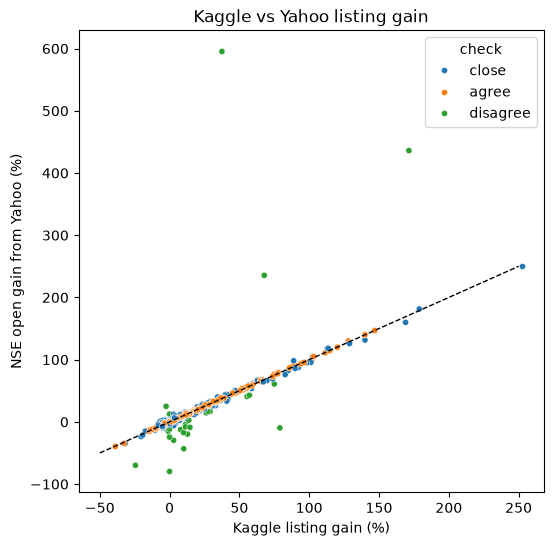

agree or close -: 95.1 %


In [33]:
# only the IPOs we could compare
c = m[m["check"].isin(["agree", "close", "disagree"])]

# each dot = one IPO, if both sources agree the dot sits on the dashed line
plt.figure(figsize=(6, 6))
sns.scatterplot(data=c, x="listing_gain_pct", y="yf_open_gain_pct", hue="check", s=20)
plt.plot([-50, 250], [-50, 250], "k--", lw=1)
plt.title("Kaggle vs Yahoo listing gain")
plt.xlabel("Kaggle listing gain (%)")
plt.ylabel("NSE open gain from Yahoo (%)")
plt.show()

print("agree or close -:", round(c["check"].isin(["agree", "close"]).mean() * 100, 1), "%")

In [34]:
# the ones that disagree - checked a few of these by hand in the news
m[m["check"] == "disagree"][["ipo_name", "symbol", "offer_price", "list_price", "open", "listing_gain_pct",
                             "yf_open_gain_pct"]].head(10)

,ipo_name,symbol,offer_price,list_price,open,listing_gain_pct,yf_open_gain_pct
22,IL&FS Transportation Networks Limited,IL&FSTRANS,258.0,287.00,246.614212,11.24,-4.413096
24,Persistent Systems Limited,PERSISTENT,310.0,400.00,361.600006,29.03,16.645163
53,Cantabil Retail India Ltd,CANTABIL,135.0,133.80,114.700003,-0.89,-15.037035
55,Va Tech Wabag Ltd,WABAG,1310.0,1655.00,1500.000000,26.34,14.503817
56,Ashoka Buildcon Ltd,ASHOKA,324.0,333.55,228.000000,2.95,-29.629630
63,Shah Metacorp Ltd,SHAH,71.0,76.60,62.188578,7.89,-12.410454
65,Gravita India Ltd,GRAVITA,125.0,218.75,201.100006,75.00,60.880005
67,RPP Infra Projects Ltd,RPPINFRA,75.0,75.00,56.590019,0.00,-24.546641
71,A2Z Infra Engineering Ltd,A2ZINFRA,400.0,390.00,500.000000,-2.50,25.000000
72,Ravikumar Distilleries Ltd,RKDL,64.0,64.00,72.000000,0.00,12.500000


**Observation:** **95.1%** of the checkable IPOs agree or are close.

For the big disagreements I checked a few manually against news reports of the listing price - CDSL listed at
250, Paras Defence at 475, Nazara at 1,971, Bansal Wire at 352. **Kaggle was right**, Yahoo's split history was
wrong (or applied twice).

**Decision - target:**

| Case | Target used | `target_source` |
|---|---|---|
| agree / close | NSE open from Yahoo | `nse_open_yahoo` |
| disagree, not on NSE list, no price | Kaggle listing gain | `kaggle_unverified` |

In [35]:
# target = the number the model will learn to predict
# if both sources agree -> use NSE open gain (verified), else keep kaggle's number (marked unverified)
ok = m["check"].isin(["agree", "close"])
m["target_gain_pct"] = np.where(ok, m["yf_open_gain_pct"], m["listing_gain_pct"])
m["target_source"] = np.where(ok, "nse_open_yahoo", "kaggle_unverified")
m["target_source"].value_counts()

target_source
nse_open_yahoo       500
kaggle_unverified    152
Name: count, dtype: int64

## Step 6: Drop Rows that Don't Belong

| Rows | Count | Reason |
|---|---|---|
| REITs / InvITs | 14 | trust units, no retail quota, different investor base |
| Vodafone Idea (2024) | 1 | FPO of an already listed company, not an IPO |
| Missing subscription / listing gain | 3 | no target to learn from |

In [36]:
# reason for removing a row, empty text = keep the row
def exclude_reason(r):
    if r["ipo_name"] == "Vodafone Idea Ltd":
        return "Follow-on public offer (FPO) of a listed company, not an IPO"
    if r["is_trust"]:
        return "REIT/InvIT: trust units, no retail quota, different investor base"
    if pd.isna(r["listing_gain_pct"]) or pd.isna(r["sub_total"]):
        return "Missing subscription or listing gain"
    return ""


# axis=1 -> run the function on every row
m["exclude_reason"] = m.apply(exclude_reason, axis=1)
m["exclude_reason"].value_counts()

exclude_reason
                                                                     634
REIT/InvIT: trust units, no retail quota, different investor base     14
Missing subscription or listing gain                                   3
Follow-on public offer (FPO) of a listed company, not an IPO           1
Name: count, dtype: int64

In [37]:
# keeping all rows in the file with the reason, feature step filters on exclude_reason
m.to_csv("../data/interim/ipos_verified.csv", index=False)

# rows the model will use
clean = m[m["exclude_reason"] == ""]
print(f"Shape of clean data -: {clean.shape}")
clean["target_source"].value_counts()

Shape of clean data -: (634, 30)


target_source
nse_open_yahoo       499
kaggle_unverified    135
Name: count, dtype: int64

## Summary

| | Count |
|---|---|
| IPOs in the Kaggle file | 652 |
| Dropped (Step 6) | 18 |
| **Clean IPOs for modelling** | **634** |
| target verified against the NSE open | 499 |
| target from Kaggle only (unverified) | 135 |

**Saved:** `data/interim/ipos_verified.csv` (all rows, with `exclude_reason`)

**Next notebook:** `02_eda.ipynb`